# Anchors and counterfactual explanations

A court uses an opaque model that predicts the risk that a defendant is rearrested within two
years, and it **predicts a rearrest when the risk is above 0.5**. To draw the two kinds of
explanation, the first part of this notebook uses a version of the model with one feature,
the age. The second part explains a prediction of the model with all features.

- An **anchor** is a rule that describes a region around the person in which the model makes
  the same decision: "as long as this holds, the decision stays".
- A **counterfactual** is the smallest change that gives the opposite decision: "if this were
  different, the decision would change".

In [1]:
import os
import warnings
from itertools import combinations, product

os.environ["TQDM_DISABLE"] = "1"  # no progress bars of the counterfactual library

import dice_ml
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from recidivism_data import FEATURES, NUMERIC, TARGET, load, load_xy
from recidivism_data.shared import age_model, opaque_model, person
from recidivism_data.theme import AQUA, BLUE, INK, INK2, MUTED, ORANGE, SERIES, use_theme

warnings.filterwarnings("ignore")
use_theme()
VIOLET = SERIES[6]

X_train, y_train = load_xy("train")
X_test, _ = load_xy("test")
f, age_risk = age_model()
ages = np.arange(18, 66.0)
curve = age_risk(ages)
people = X_test["age"].to_numpy(float)
arrest = age_risk(people) > 0.5
print("the model predicts a rearrest for the ages", ages[curve > 0.5].astype(int).tolist())


def base_plot():
    _, ax = plt.subplots(figsize=(8, 3.9))
    ax.axhline(0.5, color=MUTED, linewidth=1.2, linestyle=":")
    ax.step(ages, curve, where="mid", color=BLUE, linewidth=2.5)
    ax.annotate("opaque model f", (48, 0.36), color=BLUE, fontsize=9.5, fontweight="bold")
    ax.set(xlabel="age", ylabel="risk of rearrest", xlim=(17, 66), ylim=(0, 0.95))
    return ax

the model predicts a rearrest for the ages [18, 19, 20, 21, 22, 23]


## Anchors

The quality of an anchor has two numbers. **Precision:** the share of the people in the
region who get the same decision. **Coverage:** the share of all people who are in the region.
A wider region has more coverage, but the precision decreases when the region crosses the
decision boundary.

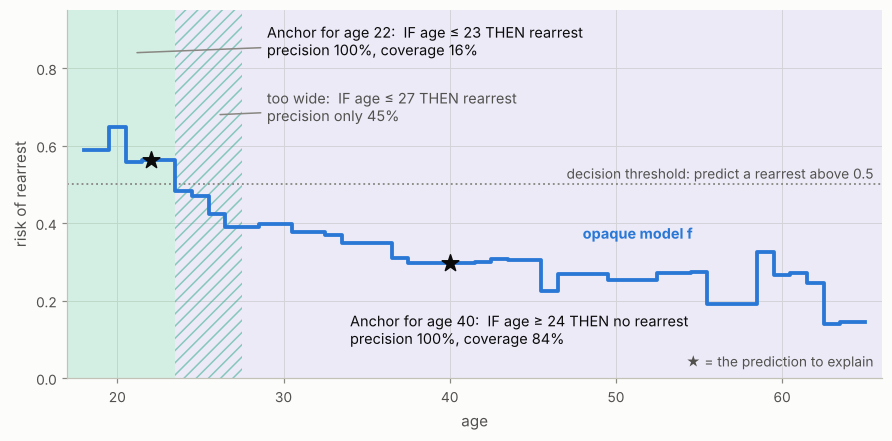

In [2]:
def interval_anchor(low: float, high: float, predicts_arrest: bool) -> tuple[float, float]:
    inside = (people >= low) & (people <= high)
    return np.mean(arrest[inside] == predicts_arrest), inside.mean()


precise, wide, other = (
    interval_anchor(18, 23, True),
    interval_anchor(18, 27, True),
    interval_anchor(24, 99, False),
)
ax = base_plot()
ax.axvspan(17, 23.5, color=AQUA, alpha=0.18, linewidth=0)
ax.axvspan(23.5, 27.5, facecolor="none", edgecolor=AQUA, hatch="///", alpha=0.5, linewidth=0)
ax.axvspan(23.5, 66, color=VIOLET, alpha=0.10, linewidth=0)
ax.annotate(
    "decision threshold: predict a rearrest above 0.5",
    (65.5, 0.515),
    ha="right",
    color=INK2,
    fontsize=9,
)
ax.scatter([22, 40], age_risk([22, 40]), s=130, marker="*", color=INK, zorder=5)
line = {"arrowstyle": "-", "color": MUTED}
text = f"Anchor for age 22:  IF age ≤ 23 THEN rearrest\nprecision {precise[0]:.0%}, coverage {precise[1]:.0%}"
ax.annotate(
    text, (21, 0.84), xytext=(29, 0.87), va="center", color=INK, fontsize=9.5, arrowprops=line
)
text = f"too wide:  IF age ≤ 27 THEN rearrest\nprecision only {wide[0]:.0%}"
ax.annotate(
    text, (26, 0.68), xytext=(29, 0.70), va="center", color=INK2, fontsize=9.5, arrowprops=line
)
text = f"Anchor for age 40:  IF age ≥ 24 THEN no rearrest\nprecision {other[0]:.0%}, coverage {other[1]:.0%}"
ax.annotate(text, (34, 0.17), va="top", color=INK, fontsize=9.5)
ax.annotate("★ = the prediction to explain", (65.5, 0.03), ha="right", color=INK2, fontsize=9)
plt.show()

With one feature, an anchor is an interval. With many features it is a combination of
conditions, and it must be searched for (see the second part).

## Counterfactuals

For each star, the arrow goes to the nearest age for which the model makes the opposite
decision.

age 20 (risk 0.65) -> age 24 (risk 0.48)
age 40 (risk 0.30) -> age 23 (risk 0.56)


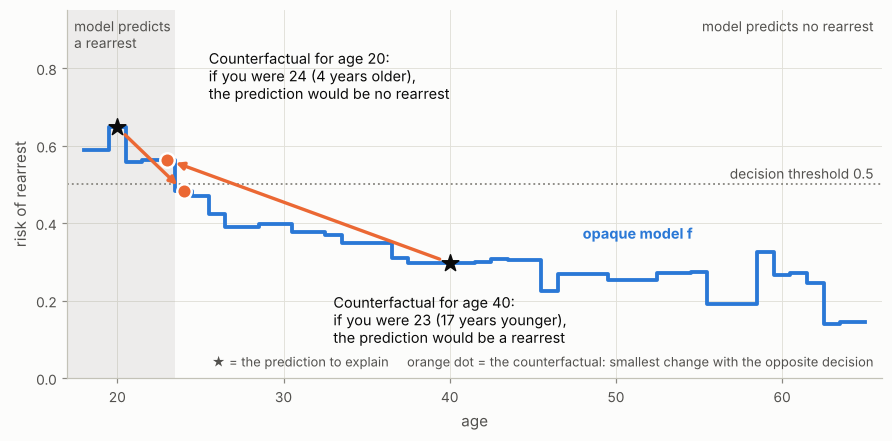

In [3]:
def counterfactual(age: float) -> float:
    """The nearest age with the opposite decision."""
    decision = age_risk([age])[0] > 0.5
    flipped = ages[(curve > 0.5) != decision]
    return flipped[np.argmin(np.abs(flipped - age))]


ax = base_plot()
ax.axvspan(17, 23.5, color=MUTED, alpha=0.13, linewidth=0)
ax.annotate("model predicts\na rearrest", (17.4, 0.93), va="top", color=INK2, fontsize=9)
ax.annotate(
    "model predicts no rearrest", (65.5, 0.93), va="top", ha="right", color=INK2, fontsize=9
)
ax.annotate("decision threshold 0.5", (65.5, 0.515), ha="right", color=INK2, fontsize=9)
for age, where in [(20, (25.5, 0.78)), (40, (33, 0.15))]:
    cf = counterfactual(age)
    y, y_cf = age_risk([age])[0], age_risk([cf])[0]
    arrow = {"arrowstyle": "-|>", "color": ORANGE, "linewidth": 2.2, "shrinkA": 7, "shrinkB": 6}
    ax.annotate("", (cf, y_cf), xytext=(age, y), arrowprops=arrow)
    ax.scatter([age], [y], s=130, marker="*", color=INK, zorder=5)
    ax.scatter([cf], [y_cf], s=90, color=ORANGE, edgecolor="white", linewidth=1.6, zorder=6)
    change = f"{cf - age:.0f} years older" if cf > age else f"{age - cf:.0f} years younger"
    outcome = "a rearrest" if y_cf > 0.5 else "no rearrest"
    text = f"Counterfactual for age {age}:\nif you were {cf:.0f} ({change}),\nthe prediction would be {outcome}"
    ax.annotate(text, where, va="center", color=INK, fontsize=9.5)
    print(f"age {age} (risk {y:.2f}) -> age {cf:.0f} (risk {y_cf:.2f})")
note = "★ = the prediction to explain     orange dot = the counterfactual: smallest change with the opposite decision"
ax.annotate(note, (65.5, 0.03), ha="right", color=INK2, fontsize=8.5)
plt.show()

The two examples also show the limit of counterfactuals as advice: the 20-year-old can wait
four years, but nobody can become 17 years younger. With one feature there is only one
counterfactual for each person. With many features there are many, and most of them are not
actionable.

## An anchor for a prediction of the model with all features

The person is a 24-year-old unemployed man with five priors and a drug charge. The search
starts with no condition and adds, one at a time, the fact about him that increases the
precision most, until 95% of "people like him" get the same prediction.

In [4]:
model = opaque_model()
him = person().iloc[0]
rng = np.random.default_rng(0)

# Candidate facts about this person: his category, or the range that his number is in.
PREDICATES = {
    "age <= 25": X_train["age"] <= 25,
    "priors_count >= 4": X_train["priors_count"] >= 4,
    "juvenile_priors = 0": X_train["juvenile_priors"] == 0,
    "age_at_first_arrest <= 17": X_train["age_at_first_arrest"] <= 17,
    "sex = male": X_train["sex"] == "male",
    "charge_type = drug": X_train["charge_type"] == "drug",
    "charge_degree = felony": X_train["charge_degree"] == "felony",
    "employed = 0": X_train["employed"] == 0,
    "in_treatment = 0": X_train["in_treatment"] == 0,
    "county = south": X_train["county"] == "south",
}


def precision(anchor: list[str], n: int = 4000) -> float:
    """Share of 'people like him' with the same prediction: the facts of the anchor hold,
    each other feature is a random value from the training data."""
    sample = pd.DataFrame({f: rng.choice(X_train[f].to_numpy(), n) for f in FEATURES})
    for name in anchor:
        feature = name.split(" ")[0]
        sample[feature] = rng.choice(X_train.loc[PREDICATES[name], feature].to_numpy(), n)
    return float(np.mean(model.predict(sample) == 1))


def coverage(anchor: list[str]) -> float:
    return float(np.logical_and.reduce([PREDICATES[name] for name in anchor]).mean())

### The prediction

In [5]:
print("  ", him.to_dict())
print(f"   P(rearrest) = {model.predict_proba(person())[0, 1]:.2f}: the model predicts a rearrest.")
print(f"   with no fact fixed, {precision([]):.0%} of random people get the same prediction")

   {'age': 24, 'sex': 'male', 'priors_count': 5, 'juvenile_priors': 0, 'age_at_first_arrest': 17, 'charge_degree': 'felony', 'charge_type': 'drug', 'employed': 0, 'in_treatment': 0, 'county': 'south'}
   P(rearrest) = 0.69: the model predicts a rearrest.
   with no fact fixed, 20% of random people get the same prediction


### Greedy search: add the fact that increases the precision most, until 95%

In [6]:
anchor: list[str] = []
while precision(anchor) < 0.95 and len(anchor) < len(PREDICATES):
    best = max((p for p in PREDICATES if p not in anchor), key=lambda p: precision([*anchor, p]))
    anchor.append(best)
    print(f"   + {best:<28} precision {precision(anchor):.0%}, coverage {coverage(anchor):.1%}")

   + priors_count >= 4            precision 44%, coverage 17.4%
   + age <= 25                    precision 67%, coverage 3.8%


   + age_at_first_arrest <= 17    precision 92%, coverage 3.7%
   + employed = 0                 precision 97%, coverage 2.7%


### The anchor

In [7]:
print(f"   IF {' AND '.join(anchor)}")
print("   THEN the model predicts a rearrest, whatever the other features are")
print(f"   precision {precision(anchor, 20000):.0%}: how often the rule holds for such people")
print(f"   coverage {coverage(anchor):.1%}: the share of all people to which the rule applies")

   IF priors_count >= 4 AND age <= 25 AND age_at_first_arrest <= 17 AND employed = 0
   THEN the model predicts a rearrest, whatever the other features are


   precision 97%: how often the rule holds for such people
   coverage 2.7%: the share of all people to which the rule applies


### Compare with the other explanations of the same prediction

In [8]:
others = [p for p in PREDICATES if p not in anchor]
print(f"   not necessary for the prediction: {', '.join(others)}")
print("   feature influence (LIME, SHAP): how much each feature pushed")
print("   counterfactual: what to change for a different prediction")
print("   anchor: which facts are enough to keep the prediction")

   not necessary for the prediction: juvenile_priors = 0, sex = male, charge_type = drug, charge_degree = felony, in_treatment = 0, county = south
   feature influence (LIME, SHAP): how much each feature pushed
   counterfactual: what to change for a different prediction
   anchor: which facts are enough to keep the prediction


## Counterfactuals for the same prediction

What must be different for the opposite prediction? There are many answers, and most of them
are not possible for this person.

In [9]:
one = person()


def risk(X: pd.DataFrame) -> float:
    return model.predict_proba(X)[:, 1]


def changes(cf: pd.Series) -> str:
    original = one.iloc[0]
    return ", ".join(f"{f}: {original[f]} -> {cf[f]}" for f in FEATURES if cf[f] != original[f])


def problems(cf: pd.Series) -> str:
    original, found = one.iloc[0], []
    if cf["age_at_first_arrest"] > cf["age"]:
        found.append("impossible: first arrest after the current age")
    elif cf["age_at_first_arrest"] != original["age_at_first_arrest"]:
        found.append("the past cannot change")
    if (
        cf["priors_count"] < original["priors_count"]
        or cf["juvenile_priors"] != original["juvenile_priors"]
    ):
        found.append("priors cannot go away")
    if cf["age"] < original["age"]:
        found.append("nobody gets younger")
    if cf["age"] > original["age"]:
        found.append(f"wait {cf['age'] - original['age']} years")
    if cf["sex"] != original["sex"] or cf["county"] != original["county"]:
        found.append("not a reasonable demand")
    if (
        cf["charge_type"] != original["charge_type"]
        or cf["charge_degree"] != original["charge_degree"]
    ):
        found.append("the charge is given")
    return "; ".join(found) or "actionable"

### The prediction

In [10]:
print("  ", one.iloc[0].to_dict())
print(f"   P(rearrest) = {risk(one)[0]:.2f}: the model predicts a rearrest.")
print("   Question of the defendant: what must be different for the opposite prediction?")

   {'age': 24, 'sex': 'male', 'priors_count': 5, 'juvenile_priors': 0, 'age_at_first_arrest': 17, 'charge_degree': 'felony', 'charge_type': 'drug', 'employed': 0, 'in_treatment': 0, 'county': 'south'}
   P(rearrest) = 0.69: the model predicts a rearrest.
   Question of the defendant: what must be different for the opposite prediction?


### Search by hand: change one feature, then two (growing distance)

In [11]:
values = {f: sorted(X_train[f].unique()) for f in FEATURES}
found = []
for size in [1, 2]:
    for group in combinations(FEATURES, size):
        if any(set(f) <= set(group) for f, _ in found):
            continue  # a subset of these features is enough already
        candidates = pd.DataFrame(list(product(*(values[f] for f in group))), columns=list(group))
        varied = pd.concat([one] * len(candidates), ignore_index=True).assign(**candidates)
        flipped = varied[risk(varied) < 0.5]
        if len(flipped):
            numeric = [f for f in group if f in NUMERIC]
            step = (
                (flipped[numeric] - one[numeric].iloc[0]).abs().sum(axis=1)
                if numeric
                else flipped.index
            )
            found.append((group, flipped.loc[pd.Series(step, index=flipped.index).idxmin()]))
    print(
        f"   with {size} changed feature(s): {sum(len(g) == size for g, _ in found)} counterfactual(s)"
    )
for group, cf in found:
    print(
        f"   - {changes(cf):<58} P = {risk(cf.to_frame().T.astype(one.dtypes))[0]:.2f}  [{problems(cf)}]"
    )
actionable = sum(problems(cf) == "actionable" for _, cf in found)
print(f"   {len(found)} different smallest changes, {actionable} of them actionable:")
print("   which one is 'the' explanation? (Rashomon effect)")

   with 1 changed feature(s): 1 counterfactual(s)


   with 2 changed feature(s): 18 counterfactual(s)
   - age_at_first_arrest: 17 -> 37                              P = 0.49  [impossible: first arrest after the current age]
   - age: 24 -> 36, sex: male -> female                         P = 0.45  [wait 12 years; not a reasonable demand]
   - age: 24 -> 25, priors_count: 5 -> 0                        P = 0.49  [priors cannot go away; wait 1 years]
   - age: 24 -> 70, charge_degree: felony -> misdemeanor        P = 0.48  [wait 46 years; the charge is given]
   - age: 24 -> 33, charge_type: drug -> traffic                P = 0.44  [wait 9 years; the charge is given]
   - age: 24 -> 46, employed: 0 -> 1                            P = 0.49  [wait 22 years]
   - age: 24 -> 33, in_treatment: 0 -> 1                        P = 0.48  [wait 9 years]
   - sex: male -> female, priors_count: 5 -> 1                  P = 0.46  [priors cannot go away; not a reasonable demand]
   - sex: male -> female, charge_type: drug -> traffic          P = 0.46  [n

### DiCE: a library that searches for a diverse set of counterfactuals

In [12]:
data = dice_ml.Data(
    dataframe=X_train.assign(**{TARGET: y_train}), continuous_features=NUMERIC, outcome_name=TARGET
)
dice = dice_ml.Dice(data, dice_ml.Model(model=model, backend="sklearn"), method="random")
result = dice.generate_counterfactuals(
    one, total_CFs=5, desired_class="opposite", random_seed=1, verbose=False
)
for _, cf in result.cf_examples_list[0].final_cfs_df.iterrows():
    print(f"   - {changes(cf):<58} [{problems(cf)}]")
print("   each of them changes the prediction, but most ask for something impossible")

   - age: 24 -> 54, age_at_first_arrest: 17 -> 72               [impossible: first arrest after the current age; wait 30 years]
   - age: 24 -> 49, in_treatment: 0 -> 1                        [wait 25 years]
   - age_at_first_arrest: 17 -> 28, in_treatment: 0 -> 1        [impossible: first arrest after the current age]
   - age_at_first_arrest: 17 -> 65                              [impossible: first arrest after the current age]
   - age_at_first_arrest: 17 -> 39                              [impossible: first arrest after the current age]
   each of them changes the prediction, but most ask for something impossible


### Actionable counterfactuals: only what the defendant can change

In [13]:
print("   allowed: get a job, start treatment, wait up to 6 years")
genetic = dice_ml.Dice(data, dice_ml.Model(model=model, backend="sklearn"), method="genetic")
result = genetic.generate_counterfactuals(
    one,
    total_CFs=3,
    desired_class="opposite",
    features_to_vary=["employed", "in_treatment", "age"],
    permitted_range={"age": [int(one["age"].iloc[0]), 30]},
    verbose=False,
)
for _, cf in result.cf_examples_list[0].final_cfs_df.iterrows():
    row = cf[FEATURES].to_frame().T.astype(one.dtypes)
    print(f"   - {changes(cf):<58} P = {risk(row)[0]:.2f}")
for label, change in [
    ("job only", {"employed": 1}),
    ("treatment only", {"in_treatment": 1}),
    ("job and treatment", {"employed": 1, "in_treatment": 1}),
]:
    print(f"   check: {label:<18} P = {risk(one.assign(**change))[0]:.2f}")

   allowed: get a job, start treatment, wait up to 6 years


   - employed: 0 -> 1, in_treatment: 0 -> 1                     P = 0.41
   - age: 24 -> 25, employed: 0 -> 1, in_treatment: 0 -> 1      P = 0.41
   - age: 24 -> 26, employed: 0 -> 1, in_treatment: 0 -> 1      P = 0.39
   check: job only           P = 0.59
   check: treatment only     P = 0.54
   check: job and treatment  P = 0.41


### Sometimes there is no actionable counterfactual

In [14]:
df = load().query("split == 'test'")
high = df[FEATURES][risk(df[FEATURES]) > 0.5]
best = high.assign(employed=1, in_treatment=1)
share = (risk(best) < 0.5).mean()
print(f"   {len(high)} people in the test data have a predicted rearrest")
print(f"   with a job and treatment, the prediction changes for {share:.0%} of them")
print(f"   for the other {1 - share:.0%}, the only honest answer is: nothing that you can do now")

   678 people in the test data have a predicted rearrest
   with a job and treatment, the prediction changes for 61% of them
   for the other 39%, the only honest answer is: nothing that you can do now
